# Spotify Genre Classification: Modular Model Training

This notebook builds a reproducible baseline for comparing K-Nearest Neighbors, Decision Tree, Logistic Regression, and Random Forest classifiers. Shared data preparation and evaluation code is kept separate from each model factory so teammates can add or adjust one model without changing the rest of the run.

**Workflow:** configure the run, explore the data, prepare a stratified train/test split, register model pipelines, train available models, and compare accuracy, precision, recall, and F1-score.

## 1. Configuration

Use `USE_FULL_DATA = False` for faster exploratory runs. Set it to `True` for final results after the notebook has been validated. Keep `FEATURES` easy to edit so feature engineering can be tested without changing model code.

In [14]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score, classification_report, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42
USE_FULL_DATA = False
SAMPLE_SIZE = 10_000
TEST_SIZE = 0.20
TARGET = "track_genre"
DATA_PATH = Path("data/spotify-tracks-dataset.csv")
FEATURES = [
    "danceability", "energy", "loudness", "speechiness",
    "acousticness", "instrumentalness", "liveness", "valence",
    "tempo", "duration_ms",
] # easy to edit feature list if we decide to add or remove features in the future

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.max_columns", 100)

## 2. Load and explore the dataset

The path is resolved from the project directory so the notebook works with the CSV currently stored beside it. The checks below preserve the useful exploration from the original notebook.

Rows and columns: (114000, 22)


,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


,data type
Unnamed: 0.1,int64
Unnamed: 0,int64
track_id,str
artists,str
album_name,str
track_name,str
popularity,int64
duration_ms,int64
explicit,bool
danceability,float64


Missing values: 3
Duplicate rows: 0
Number of genres: 114


,tracks per genre
count,114.0
mean,1000.0
std,0.0
min,1000.0
25%,1000.0
50%,1000.0
75%,1000.0
max,1000.0


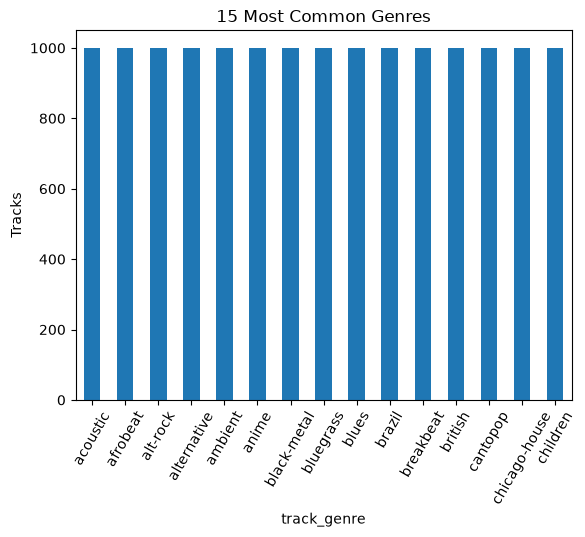

,count,mean,std,min,25%,50%,75%,max
danceability,114000.0,0.566800,0.173542,0.000,0.45600,0.580000,0.6950,0.985
energy,114000.0,0.641383,0.251529,0.000,0.47200,0.685000,0.8540,1.000
loudness,114000.0,-8.258960,5.029337,-49.531,-10.01300,-7.004000,-5.0030,4.532
speechiness,114000.0,0.084652,0.105732,0.000,0.03590,0.048900,0.0845,0.965
acousticness,114000.0,0.314910,0.332523,0.000,0.01690,0.169000,0.5980,0.996
instrumentalness,114000.0,0.156050,0.309555,0.000,0.00000,0.000042,0.0490,1.000
liveness,114000.0,0.213553,0.190378,0.000,0.09800,0.132000,0.2730,1.000
valence,114000.0,0.474068,0.259261,0.000,0.26000,0.464000,0.6830,0.995
tempo,114000.0,122.147837,29.978197,0.000,99.21875,122.017000,140.0710,243.372
duration_ms,114000.0,228029.153114,107297.712645,0.000,174066.00000,212906.000000,261506.0000,5237295.000


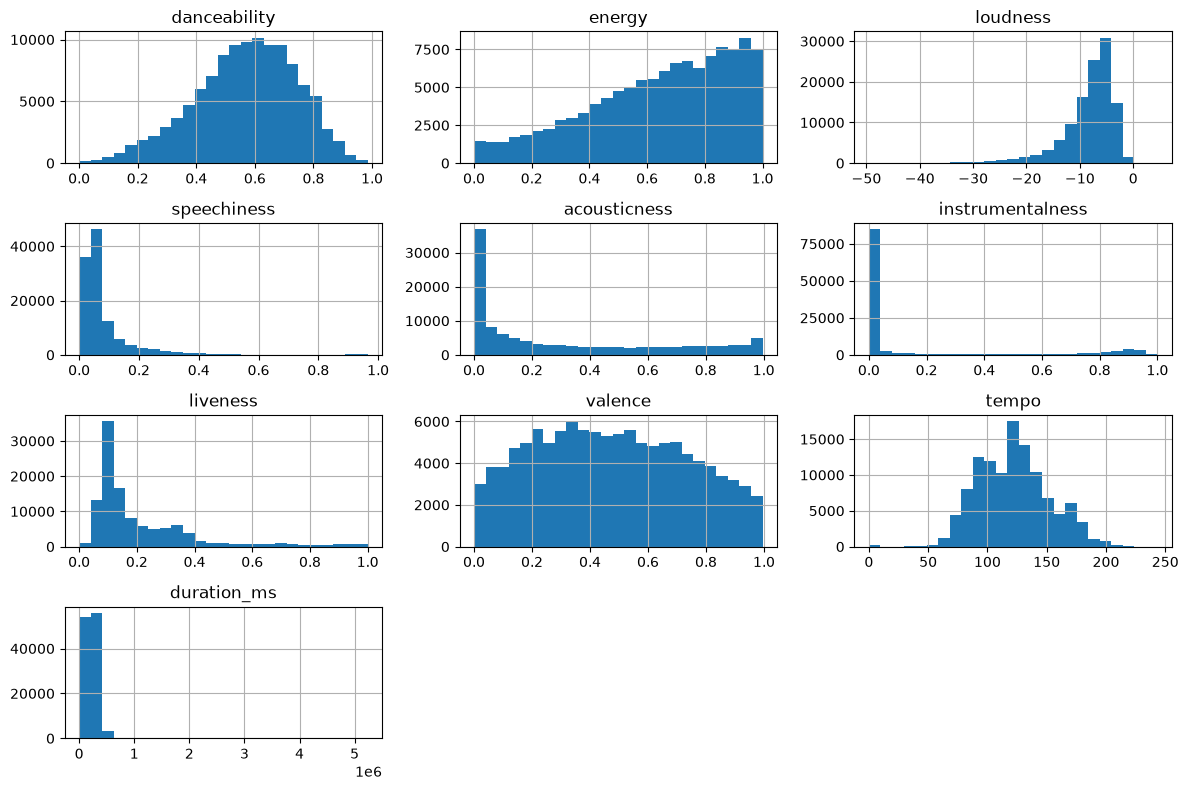

In [15]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found at {DATA_PATH.resolve()}")

# Processing ported over from original notebook in initial_exploration.ipynb

df = pd.read_csv(DATA_PATH)
print("Rows and columns:", df.shape)
display(df.head())

display(df.dtypes.to_frame("data type"))
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

genre_counts = df[TARGET].value_counts()
print("Number of genres:", df[TARGET].nunique())
display(genre_counts.describe().to_frame("tracks per genre"))
genre_counts.head(15).plot(kind="bar", title="15 Most Common Genres", ylabel="Tracks", rot=60);
plt.show()

available_features = [feature for feature in FEATURES if feature in df.columns]
missing_features = sorted(set(FEATURES) - set(available_features))
if missing_features:
    raise KeyError(f"Configured features are missing from the dataset: {missing_features}")

display(df[available_features].describe().T)
df[available_features].hist(figsize=(12, 8), bins=25)
plt.tight_layout()
plt.show()

## 3. Prepare a reproducible modeling dataset

A stratified sample keeps every genre represented during exploratory runs. The final train/test split is also stratified so class proportions remain comparable between partitions.

In [16]:
model_df = df[available_features + [TARGET]].dropna().copy()
if not USE_FULL_DATA and len(model_df) > SAMPLE_SIZE:
    _, model_df = train_test_split(
        model_df,
        test_size=SAMPLE_SIZE,
        stratify=model_df[TARGET],
        random_state=RANDOM_STATE,
    )

X = model_df[available_features]
y = model_df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f"Modeling rows: {len(model_df):,}")
print(f"Training rows: {len(X_train):,}; test rows: {len(X_test):,}")
print(f"Features: {available_features}")

Modeling rows: 10,000
Training rows: 8,000; test rows: 2,000
Features: ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']


## 4. Shared preprocessing and model registry for factory design pattern

Each factory returns a complete pipeline. This prevents preprocessing leakage and gives each of us an isolated implementation for each model. To exclude a model set its registry value to `None` and the runner will skip it without stopping the notebook. I'm not sure if this kind of OOP is the best option for notebooks but it works for now and helps us separate our work. 

In [17]:
def make_preprocessor(feature_names):
    # using StandardScaler to scale numeric audio features inside each model pipeline.
    return ColumnTransformer(
        transformers=[("audio_features", StandardScaler(), feature_names)],
        remainder="drop",
    )


def make_knn_pipeline(feature_names):
    preprocessor = make_preprocessor(feature_names)
    knn = KNeighborsClassifier(n_neighbors=7, weights="distance")
    return Pipeline([("preprocessor", preprocessor), ("knn", knn)])


def make_decision_tree_pipeline(feature_names):
    preprocessor = make_preprocessor(feature_names)
    decision_tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
    return Pipeline([("preprocessor", preprocessor), ("decision_tree", decision_tree)])


def make_logistic_regression_pipeline(feature_names):
    return None


def make_random_forest_pipeline(feature_names):
    return None


# As we implement pipelines, replance none with the function name in the registry below. 
# The runner will skip any models that are set to None.
MODEL_FACTORIES = {
    "KNN": make_knn_pipeline,
    "Decision Tree": make_decision_tree_pipeline,
    "Logistic Regression": None,
    "Random Forest": None,
}



## 5. Train and evaluate available models

Macro-averaged precision, recall, and F1-score treat each genre equally, which is useful when comparing performance across many classes. The full classification report is retained per model for deeper analysis.

In [18]:
def evaluate_model(name, factory, feature_names, X_train, X_test, y_train, y_test):
    if factory is None:
        print(f"Skipping {name}: no implementation registered.")
        return None, None

    pipeline = factory(feature_names)
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, predictions, average="macro", zero_division=0
    )
    metrics = {
        "model": name,
        "accuracy": accuracy_score(y_test, predictions),
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1,
    }
    return pipeline, metrics


trained_models = {}
metric_rows = []
classification_reports = {}

for model_name, model_factory in MODEL_FACTORIES.items():
    trained_model, metrics = evaluate_model(
        model_name, model_factory, available_features,
        X_train, X_test, y_train, y_test,
    )
    if trained_model is not None:
        trained_models[model_name] = trained_model
        metric_rows.append(metrics)
        classification_reports[model_name] = classification_report(
            y_test, trained_model.predict(X_test), zero_division=0, output_dict=True
        )

if metric_rows:
    results = (
        pd.DataFrame(metric_rows)
        .set_index("model")
        .sort_values("f1_macro", ascending=False)
    )
else:
    results = pd.DataFrame(
        columns=[
            "accuracy",
            "precision_macro",
            "recall_macro",
            "f1_macro",
        ]
    )
    results.index.name = "model"
display(results.style.format("{:.4f}"))


Skipping Logistic Regression: no implementation registered.
Skipping Random Forest: no implementation registered.


,accuracy,precision_macro,recall_macro,f1_macro
model,,,,
KNN,0.1455,0.1375,0.1453,0.1380
Decision Tree,0.1100,0.1125,0.1098,0.1090


## 6. Compare baseline performance

This chart is intentionally based on the shared results table so adding a registered model automatically includes it in the comparison. Additionally, the best-performing model is identified based on its macro F1-score, and a ranked table is generated to facilitate the comparison of all evaluation metrics.

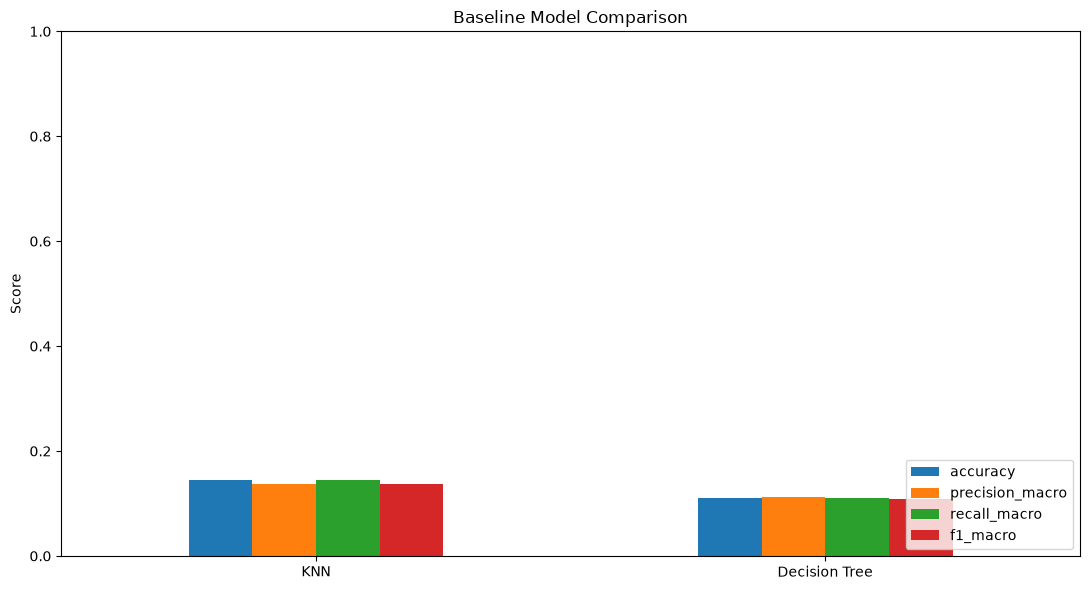

Best performing model: KNN
Macro F1-Score: 0.138

Model Rankings:


,accuracy,precision_macro,recall_macro,f1_macro
model,,,,
KNN,0.1455,0.137476,0.145282,0.137963
Decision Tree,0.1100,0.112529,0.109792,0.109024


In [19]:
if results.empty:
    print("No models were trained. Register at least one model factory to create results.")
else:
    results.plot(kind="bar", figsize=(11, 6), ylim=(0, 1), rot=0)
    plt.title("Baseline Model Comparison")
    plt.ylabel("Score")
    plt.xlabel("")
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()
    best_model = results["f1_macro"].idxmax()
    print("Best performing model:", best_model)
    print("Macro F1-Score:", round(results.loc[best_model, "f1_macro"], 4))
    print("\nModel Rankings:")
    display(results.sort_values(by="f1_macro", ascending=False))


## 7. Collaboration notes and next steps

- Add model-specific hyperparameters inside that model's factory rather than changing the shared runner.
- Add feature engineering by editing `FEATURES` or creating a new preprocessor, then keep the train/test split unchanged for fair comparisons.
- Keep `RANDOM_STATE` fixed when comparing models.
- Use `USE_FULL_DATA = True` only for final runs after validating the notebook on the stratified sample.
- Optional tuning and cross-validation can be added later around the existing registry without changing the evaluation contract.